In [2]:
library(tidyverse)

#Import dataset
wine <- read_csv("winequality-red.csv")

head(wine)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Rows: 1599 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.8,0.88,0.00,2.6,0.098,25,67,0.9968,3.20,0.68,9.8,5
7.8,0.76,0.04,2.3,0.092,15,54,0.9970,3.26,0.65,9.8,5
11.2,0.28,0.56,1.9,0.075,17,60,0.9980,3.16,0.58,9.8,6
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.4,0.66,0.00,1.8,0.075,13,40,0.9978,3.51,0.56,9.4,5


## Cleaning the Data

In [3]:
library(janitor)

wine <- wine |>
  clean_names()

names(wine)


Attaching package: ‘janitor’


The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test




[1] "fixed_acidity"        "volatile_acidity"     "citric_acid"         
 [4] "residual_sugar"       "chlorides"            "free_sulfur_dioxide" 
 [7] "total_sulfur_dioxide" "density"              "p_h"                 
[10] "sulphates"            "alcohol"              "quality"

In [4]:
#Count missing values in each column
colSums(is.na(wine))

#Total missing values
sum(is.na(wine))

fixed_acidity     volatile_acidity          citric_acid 
                   0                    0                    0 
      residual_sugar            chlorides  free_sulfur_dioxide 
                   0                    0                    0 
total_sulfur_dioxide              density                  p_h 
                   0                    0                    0 
           sulphates              alcohol              quality 
                   0                    0                    0

[1] 0

## Exploratory Data Analysis

### Summary Statistics for All Variables

In [5]:
#Dataset dimensions
dim(wine)

#Summary statistics
summary(wine)

[1] 1599   12

 fixed_acidity   volatile_acidity  citric_acid    residual_sugar  
 Min.   : 4.60   Min.   :0.1200   Min.   :0.000   Min.   : 0.900  
 1st Qu.: 7.10   1st Qu.:0.3900   1st Qu.:0.090   1st Qu.: 1.900  
 Median : 7.90   Median :0.5200   Median :0.260   Median : 2.200  
 Mean   : 8.32   Mean   :0.5278   Mean   :0.271   Mean   : 2.539  
 3rd Qu.: 9.20   3rd Qu.:0.6400   3rd Qu.:0.420   3rd Qu.: 2.600  
 Max.   :15.90   Max.   :1.5800   Max.   :1.000   Max.   :15.500  
   chlorides       free_sulfur_dioxide total_sulfur_dioxide    density      
 Min.   :0.01200   Min.   : 1.00       Min.   :  6.00       Min.   :0.9901  
 1st Qu.:0.07000   1st Qu.: 7.00       1st Qu.: 22.00       1st Qu.:0.9956  
 Median :0.07900   Median :14.00       Median : 38.00       Median :0.9968  
 Mean   :0.08747   Mean   :15.87       Mean   : 46.47       Mean   :0.9967  
 3rd Qu.:0.09000   3rd Qu.:21.00       3rd Qu.: 62.00       3rd Qu.:0.9978  
 Max.   :0.61100   Max.   :72.00       Max.   :289.00       Max.   :1

### Distribution of Wine Quality

quality,n,percentage
<dbl>,<int>,<dbl>
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


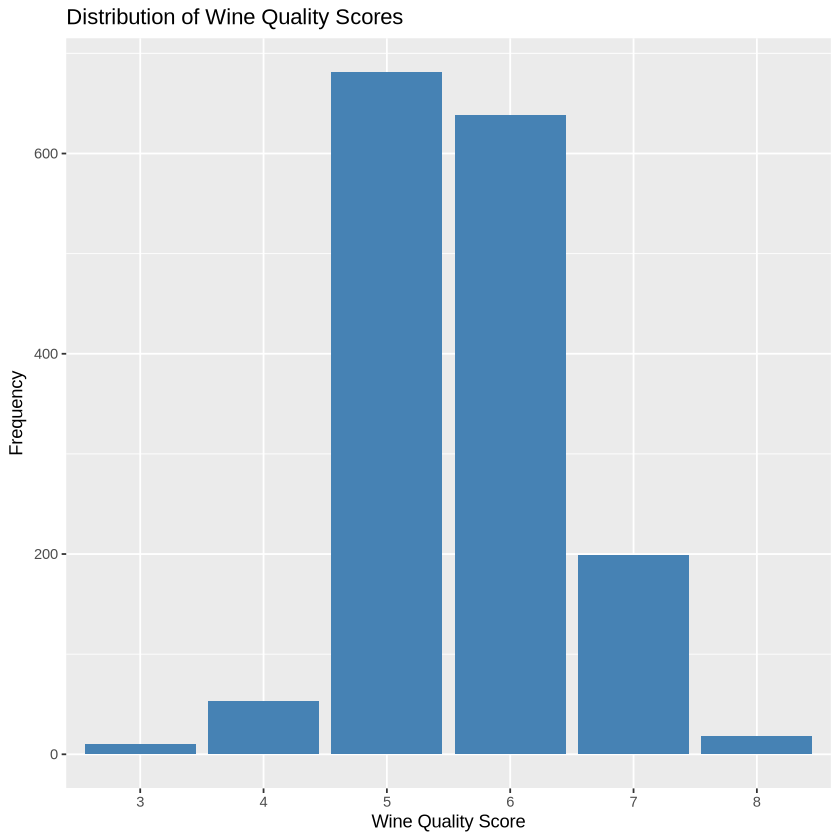

In [6]:
wine |>
  count(quality) |>
  mutate(percentage = round(n / sum(n) * 100, 2))

ggplot(wine, aes(x = factor(quality))) +
  geom_bar(fill = "steelblue") +
  labs(title = "Distribution of Wine Quality Scores",
    x = "Wine Quality Score",
    y = "Frequency")

### Distribution of Input Variables (Wine Characteristics)

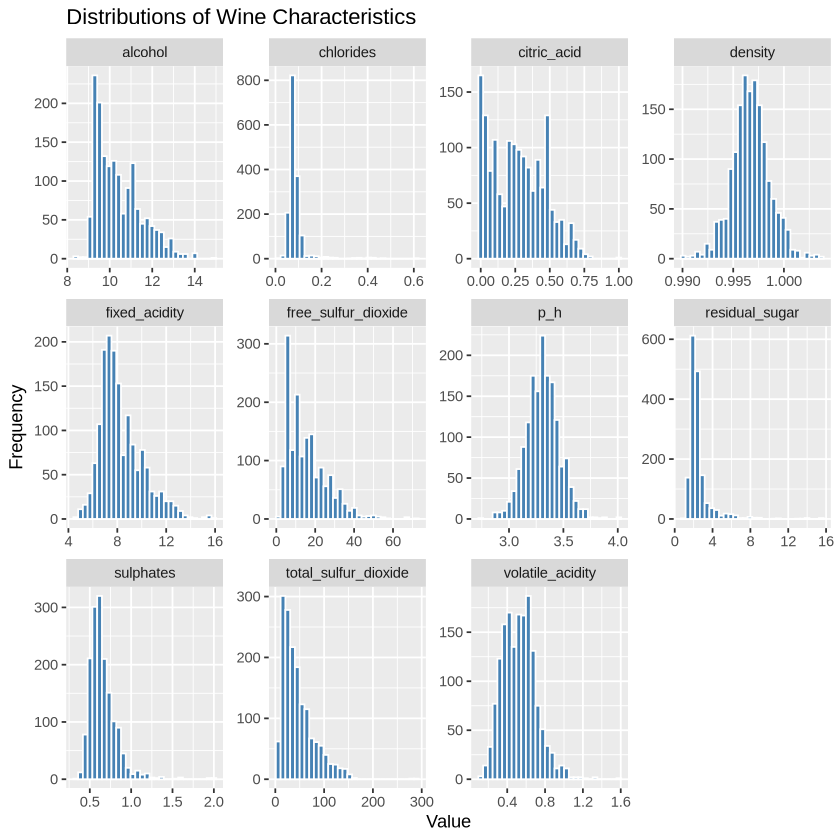

In [7]:
wine |>
  select(-quality) |>
  pivot_longer(cols = everything(),
    names_to = "variable",
    values_to = "value") |>
  ggplot(aes(x = value)) +
  geom_histogram(bins = 30,
    fill = "steelblue",
    color = "white") +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Distributions of Wine Characteristics",
    x = "Value",
    y = "Frequency") 

### Examining Some Selected Correlation Coeffecients (Pearson)

In [8]:
#Correlation between alcohol and quality
cor(wine$alcohol, wine$quality)

#Correlation between volatile acidity and quality
cor(wine$volatile_acidity, wine$quality)

#Correlation between sulphates and quality
cor(wine$sulphates, wine$quality)

[1] 0.4761663

[1] -0.3905578

[1] 0.2513971

### Creating a Correlation Plot/ HeatMap for all Wine Characteristics

Installing package into ‘/home/jupyter/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

corrplot 0.95 loaded



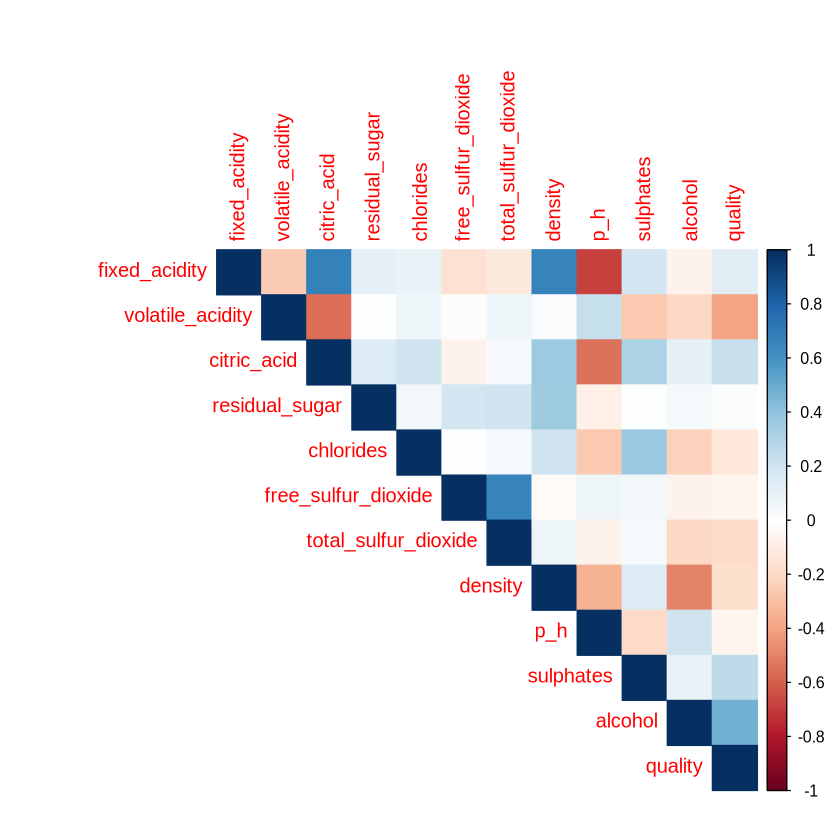

In [9]:
install.packages("corrplot")   
library(corrplot)

cor_matrix <- cor(wine)

corrplot(cor_matrix,
         method = "color",
         type = "upper")

## Multiple Linear Regression
We fit a multiple linear regression model to predict wine quality. This allows us to examine the effects of alcohol content, volatile acidity, and sulphates on perceived quality, while controlling for other variables.

In [11]:
mlr_model <- lm(quality ~ alcohol + volatile_acidity + sulphates, data = wine)
summary(mlr_model)


Call:
lm(formula = quality ~ alcohol + volatile_acidity + sulphates, 
    data = wine)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.7186 -0.3820 -0.0641  0.4746  2.1807 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)       2.61083    0.19569  13.342  < 2e-16 ***
alcohol           0.30922    0.01580  19.566  < 2e-16 ***
volatile_acidity -1.22140    0.09701 -12.591  < 2e-16 ***
sulphates         0.67903    0.10080   6.737 2.26e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.6587 on 1595 degrees of freedom
Multiple R-squared:  0.3359,	Adjusted R-squared:  0.3346 
F-statistic: 268.9 on 3 and 1595 DF,  p-value: < 2.2e-16


## Model Diagnostics and Visualization
To evaluate the fit of the multiple linear regression model, consider the residuals against fitted values to check assumptions such as equal variance.

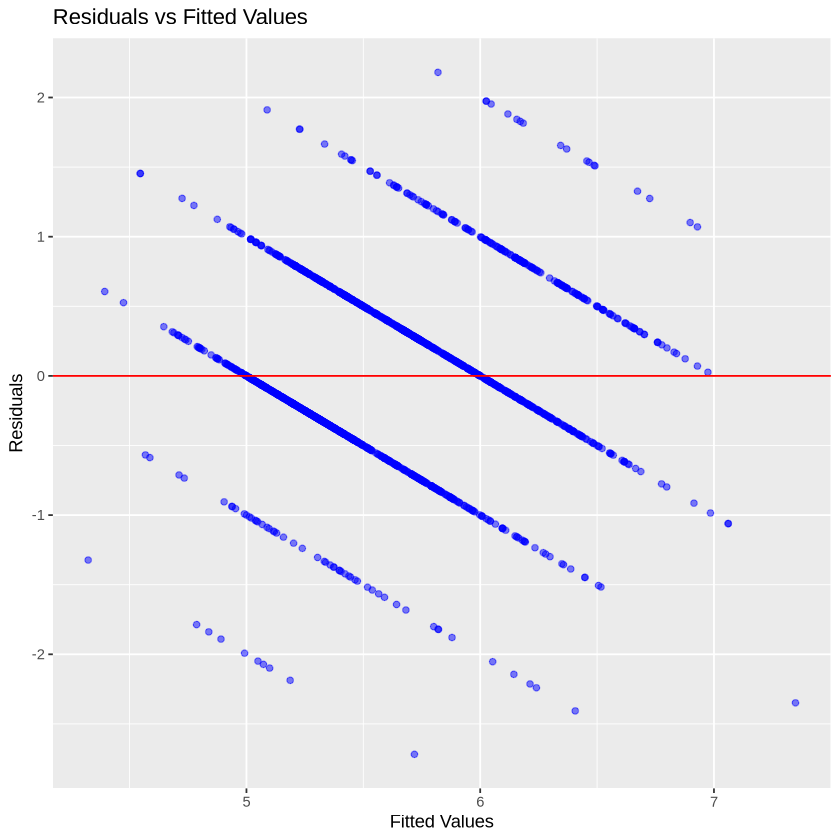

In [24]:
library(broom)
model_data <- augment(mlr_model)
ggplot(model_data, aes(x = .fitted, y = .resid)) + 
    geom_point(alpha = 0.5, color = "blue") +
    geom_hline(yintercept = 0, linetype = "solid", color = "red") +
    labs(title = "Residuals vs Fitted Values",
         x = "Fitted Values",
         y = "Residuals")

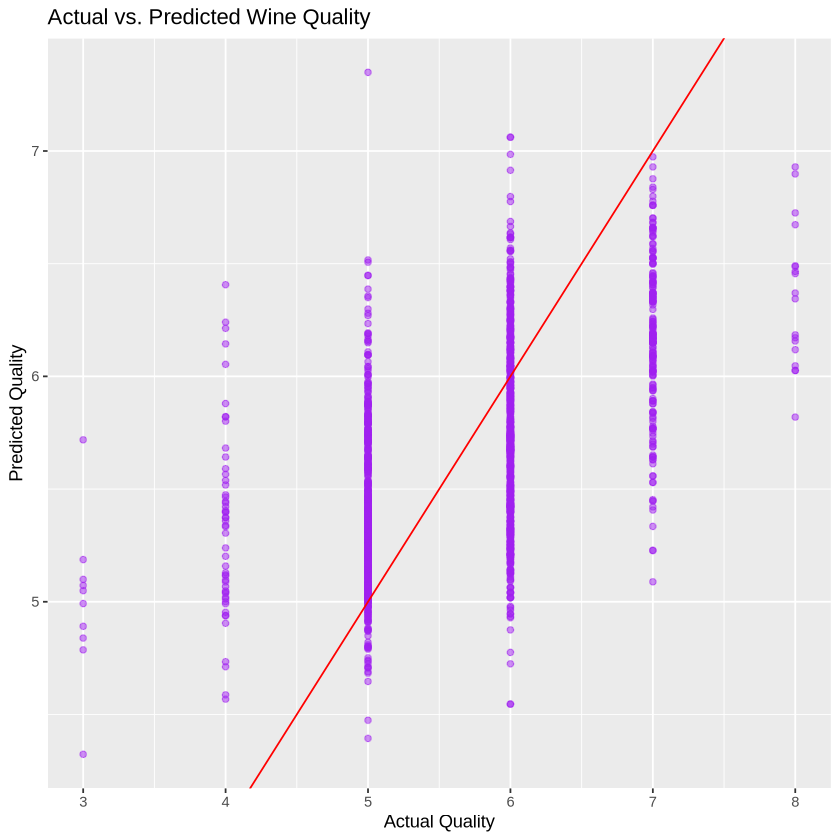

In [25]:
#Plotting actual vs predicted wine quality
ggplot(model_data, aes(x = quality, y = .fitted)) +
  geom_point(alpha = 0.5, color = "purple") +
  geom_abline(slope = 1, intercept = 0, color = "red") +
  labs(title = "Actual vs. Predicted Wine Quality",
       x = "Actual Quality",
       y = "Predicted Quality")

## Interpreting the Results
**The Overall Model:** The overall multiple linear regression model is statistically significant ($p < 0.001$), meaning our chosen predictors (alcohol, volatile acidity, and sulphates) effectively predict wine quality rather than guessing

**Coefficients and Direction:**
- **Alcohol:** Has a positive coefficient, meaning higher alcohol content is associated with higher    perceived wine quality when keeping other factors constant
- **Volatile Acidity:** Has a negative coefficient, reflecting the fact that higher volatile acidity
tends to lower quality scores. Note that volatile acidity has a vinegar-like taste
- **Sulphates:** Has a positive relationship with quality, similar to alcohol content

**Assumptions and Limiations:** Multiple linear regresion assumes a linear relationship between the predictors and quality, and that the residuals are normally distributed and share equal variance.
    

## Interpreting the Actual vs Predicted Wine Quality Plot

**Actual vs Predicted Comparison:** Each point represents a wine sample, comparing its actual quality rating on the x-axis against the quality score predicted by the multiple linear regression model on the y-axis

**The Reference Line:** The red line represents a "perfect" prediction, that is, with slope = 1. Here, the predicted scores generally trend upwards along with the line, confirming that the predictors capture meaningful patterns.



## Interpreting the Residuals vs Fitted Values Plot

The points cluster tightly along parallel diagonal "lines", the spread of the residuals are consistent. The residuals on each "line" cluster around the center and gradually taper off on each side. This suggests that the assumption of equal variance is reasonably well met. Furthermore, wine quality in the dataset is recorded as whole numbers (integers from 3 to 8), the residuals naturally form diagonal stripes rather than a cloud of points. However, the absence of any curved pattern or non-center clustering suggests that a linear approximation is a fair choice for modelling the chosen predictors.
